# Análisis exploratorio de datos


Exploración inicial de los datos

carga de datos

In [90]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

ruta_datos = Path("Base_de_datos.csv")
if not ruta_datos.exists():
    raise FileNotFoundError(f"No se encontró el archivo: {ruta_datos.resolve()}")

df = pd.read_csv(ruta_datos, encoding="utf-8-sig")
print(f"Registros: {df.shape[0]:,}  |  Columnas: {df.shape[1]}")

Registros: 10,763  |  Columnas: 23


In [91]:
display(df.head())
df.info()

,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,puntaje_datacredito,cant_creditosvigentes,huella_consulta,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,4,2025-01-07 14:40:36,"1,852,560.00",12,32,Empleado,3500000,1000000,128650,95.23,795.00,0,2,0.00,0.00,NaN,NaN,0,0,0,"916,148.00",Creciente,1
1,4,2025-01-09 11:18:48,"3,181,080.00",6,34,Empleado,5000000,2000000,441817,95.23,796.00,0,7,0.00,0.00,NaN,NaN,0,0,0,"4,473,774.00",Creciente,1
2,9,2024-12-26 18:52:57,"670,200.00",5,34,Independiente,5000000,2000000,108632,95.23,727.00,5,0,0.00,"274,561.00","274,561.00",NaN,2,0,1,NaN,NaN,1
3,9,2024-12-04 14:20:50,"506,806.80",2,25,Independiente,3000000,900000,199684,95.23,864.00,8,1,0.00,"27,564.00","27,564.00",NaN,1,0,6,NaN,NaN,1
4,4,2025-04-30 18:41:57,"999,780.00",10,26,Empleado,2000000,600000,92509,95.23,771.00,0,3,0.00,0.00,NaN,NaN,0,0,0,"61,000.00",Creciente,1


<class 'pandas.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   tipo_credito                   10763 non-null  int64  
 1   fecha_prestamo                 10763 non-null  str    
 2   capital_prestado               10763 non-null  float64
 3   plazo_meses                    10763 non-null  int64  
 4   edad_cliente                   10763 non-null  int64  
 5   tipo_laboral                   10763 non-null  str    
 6   salario_cliente                10763 non-null  int64  
 7   total_otros_prestamos          10763 non-null  int64  
 8   cuota_pactada                  10763 non-null  int64  
 9   puntaje                        10763 non-null  float64
 10  puntaje_datacredito            10757 non-null  float64
 11  cant_creditosvigentes          10763 non-null  int64  
 12  huella_consulta                10763 non-null  int64  
 1

**Qué se ve.** La base tiene **10.763 créditos** (filas) y **23 variables** (columnas): datos del préstamo (monto, plazo, cuota, fecha), del cliente (edad, tipo de trabajo, salario) y de su historial en centrales de riesgo (puntajes, saldos, créditos vigentes). La variable que se quiere predecir es `Pago_atiempo`.

**Decisión.** Los datos originales quedan guardados en `df`. Todo lo que se corrija se hará sobre una copia llamada `df_eda`.

Caracterización de las variables

In [92]:
clasificacion = {
    "tipo_credito":               ["Categórica", "Nominal politómica (6 códigos)", "Código del tipo de crédito (su significado está por confirmar)"],
    "fecha_prestamo":             ["Fecha", "Temporal", "Fecha y hora en que se otorgó el préstamo"],
    "capital_prestado":           ["Numérica", "Continua", "Monto prestado"],
    "plazo_meses":                ["Numérica", "Discreta", "Plazo del crédito en meses"],
    "edad_cliente":               ["Numérica", "Discreta", "Edad del cliente en años"],
    "tipo_laboral":               ["Categórica", "Nominal dicotómica (2 valores)", "Empleado o Independiente"],
    "salario_cliente":            ["Numérica", "Continua", "Salario del cliente"],
    "total_otros_prestamos":      ["Numérica", "Continua", "Monto de otros préstamos del cliente"],
    "cuota_pactada":              ["Numérica", "Continua", "Valor de la cuota acordada"],
    "puntaje":                    ["Numérica", "Continua", "Puntaje del cliente (origen y cálculo por confirmar)"],
    "puntaje_datacredito":        ["Numérica", "Continua", "Puntaje de la central de riesgo Datacrédito"],
    "cant_creditosvigentes":      ["Numérica", "Discreta (conteo)", "Créditos vigentes del cliente"],
    "huella_consulta":            ["Numérica", "Discreta (conteo)", "Consultas del cliente en centrales de riesgo (por confirmar)"],
    "saldo_mora":                 ["Numérica", "Continua", "Saldo en mora"],
    "saldo_total":                ["Numérica", "Continua", "Saldo total de deuda"],
    "saldo_principal":            ["Numérica", "Continua", "Saldo del capital pendiente"],
    "saldo_mora_codeudor":        ["Numérica", "Continua", "Saldo en mora del codeudor"],
    "creditos_sectorFinanciero":  ["Numérica", "Discreta (conteo)", "Créditos en el sector financiero"],
    "creditos_sectorCooperativo": ["Numérica", "Discreta (conteo)", "Créditos en el sector cooperativo"],
    "creditos_sectorReal":        ["Numérica", "Discreta (conteo)", "Créditos en el sector real"],
    "promedio_ingresos_datacredito": ["Numérica", "Continua", "Promedio de ingresos reportado por Datacrédito"],
    "tendencia_ingresos":         ["Categórica", "Ordinal (Decreciente < Estable < Creciente)", "Cómo han cambiado los ingresos del cliente"],
    "Pago_atiempo":               ["Categórica", "Dicotómica (0 / 1) — variable objetivo", "Si el cliente pagó a tiempo (el significado de 0 y 1 se confirma con la fuente)"],
}
tabla_clasificacion = pd.DataFrame.from_dict(
    clasificacion, orient="index", columns=["Tipo", "Subtipo", "Descripción"]
)
tabla_clasificacion.index.name = "Variable"
display(tabla_clasificacion)


TARGET = "Pago_atiempo"
CATEGORICAS = ["tipo_credito", "tipo_laboral", "tendencia_ingresos"]
NUMERICAS = [c for c in df.columns if c not in CATEGORICAS + [TARGET, "fecha_prestamo"]]
print(f"\n{len(NUMERICAS)} variables numéricas, {len(CATEGORICAS)} categóricas, 1 fecha y 1 variable objetivo.")

,Tipo,Subtipo,Descripción
Variable,,,
tipo_credito,Categórica,Nominal politómica (6 códigos),Código del tipo de crédito (su significado est...
fecha_prestamo,Fecha,Temporal,Fecha y hora en que se otorgó el préstamo
capital_prestado,Numérica,Continua,Monto prestado
plazo_meses,Numérica,Discreta,Plazo del crédito en meses
edad_cliente,Numérica,Discreta,Edad del cliente en años
tipo_laboral,Categórica,Nominal dicotómica (2 valores),Empleado o Independiente
salario_cliente,Numérica,Continua,Salario del cliente
total_otros_prestamos,Numérica,Continua,Monto de otros préstamos del cliente
cuota_pactada,Numérica,Continua,Valor de la cuota acordada



18 variables numéricas, 3 categóricas, 1 fecha y 1 variable objetivo.


 Valores faltantes

In [93]:
resumen_nulos = pd.DataFrame({
    "faltantes": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(2),
})
resumen_nulos = resumen_nulos[resumen_nulos["faltantes"] > 0].sort_values("porcentaje", ascending=False)
display(resumen_nulos)

,faltantes,porcentaje
tendencia_ingresos,2932,27.24
promedio_ingresos_datacredito,2930,27.22
saldo_mora_codeudor,590,5.48
saldo_principal,405,3.76
saldo_mora,156,1.45
saldo_total,156,1.45
puntaje_datacredito,6,0.06


In [94]:
print("¿Los dos campos con más vacíos coinciden?")
display(pd.crosstab(df["tendencia_ingresos"].isna(), df["promedio_ingresos_datacredito"].isna(),
                    rownames=["tendencia vacía"], colnames=["promedio vacío"]))

sin_ingresos = df["promedio_ingresos_datacredito"].isna()
comparacion = pd.DataFrame({
    "% independientes": df["tipo_laboral"].eq("Independiente").groupby(sin_ingresos).mean() * 100,
    "edad promedio": df.groupby(sin_ingresos)["edad_cliente"].mean(),
    "salario (mediana)": df.groupby(sin_ingresos)["salario_cliente"].median(),
    "salario (promedio)": df.groupby(sin_ingresos)["salario_cliente"].mean(),
    "% que pagó a tiempo": df.groupby(sin_ingresos)["Pago_atiempo"].mean() * 100,
})
comparacion.index = ["Con datos de ingresos", "Sin datos de ingresos"]
display(comparacion)

¿Los dos campos con más vacíos coinciden?


promedio vacío,False,True
tendencia vacía,,
False,7831,0
True,2,2930


,% independientes,edad promedio,salario (mediana),salario (promedio),% que pagó a tiempo
Con datos de ingresos,30.18,41.74,"3,000,000.00","9,153,811.92",95.62
Sin datos de ingresos,56.14,49.84,"3,000,000.00","38,770,867.93",94.27


Unificar la forma de representar los nulos

In [95]:

representaciones_nulas = ["", " ", "NA", "N/A", "NULL", "null", "None", "nan", "NaN", "?", "-"]
columnas_no_numericas = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
encontrados = {c: int(df[c].astype("string").str.strip().isin(representaciones_nulas).sum())
               for c in columnas_no_numericas}
print("Textos que significan 'vacío' por columna:", encontrados)


sospechosos = pd.Series({
    "salario_cliente igual a 0": (df["salario_cliente"] == 0).sum(),
    "puntaje_datacredito igual a 0": (df["puntaje_datacredito"] == 0).sum(),
    "puntaje_datacredito negativo": (df["puntaje_datacredito"] < 0).sum(),
    "promedio_ingresos_datacredito igual a 0": (df["promedio_ingresos_datacredito"] == 0).sum(),
    "total_otros_prestamos igual a 0": (df["total_otros_prestamos"] == 0).sum(),
}, name="registros")
display(sospechosos.to_frame())

Textos que significan 'vacío' por columna: {'fecha_prestamo': 0, 'tipo_laboral': 0, 'tendencia_ingresos': 0}


,registros
salario_cliente igual a 0,24
puntaje_datacredito igual a 0,145
puntaje_datacredito negativo,1
promedio_ingresos_datacredito igual a 0,7
total_otros_prestamos igual a 0,445


In [96]:
df_eda = df.copy()
df_eda.loc[df_eda["salario_cliente"] == 0, "salario_cliente"] = np.nan
df_eda.loc[df_eda["puntaje_datacredito"] <= 0, "puntaje_datacredito"] = np.nan
print("Salarios faltantes ahora:", df_eda["salario_cliente"].isna().sum())
print("Puntajes de Datacrédito faltantes ahora:", df_eda["puntaje_datacredito"].isna().sum())

Salarios faltantes ahora: 24
Puntajes de Datacrédito faltantes ahora: 152


 Registros duplicados

In [97]:
print("Registros duplicados:", df.duplicated().sum())

Registros duplicados: 0


No hay filas repetidas, así que no se elimina ninguna.

Corregir los tipos de datos

In [98]:
categorias_validas = ["Decreciente", "Estable", "Creciente"]
if "df_eda" not in globals():
    df_eda = df.copy()
    df_eda.loc[df_eda["salario_cliente"] == 0, "salario_cliente"] = np.nan
    df_eda.loc[df_eda["puntaje_datacredito"] <= 0, "puntaje_datacredito"] = np.nan

no_validos = (
    df_eda["tendencia_ingresos"].notna()
    & ~df_eda["tendencia_ingresos"].isin(categorias_validas)
)
print("Valores de tendencia_ingresos que no son una categoría válida:", no_validos.sum())
print("Los más frecuentes:")
display(df_eda.loc[no_validos, "tendencia_ingresos"].value_counts().head(8).to_frame("registros"))

Valores de tendencia_ingresos que no son una categoría válida: 58
Los más frecuentes:


,registros
tendencia_ingresos,
0,7
8315,6
1000000,4
9147,2
158042,1
3978,1
168750,1
-28589,1


In [99]:

df_eda["fecha_prestamo"] = pd.to_datetime(df_eda["fecha_prestamo"], errors="coerce")
print("Fechas que no se pudieron convertir:", df_eda["fecha_prestamo"].isna().sum())
print("Rango de fechas:", df_eda["fecha_prestamo"].min().date(), "a", df_eda["fecha_prestamo"].max().date())


df_eda["tendencia_invalida"] = no_validos
df_eda.loc[no_validos, "tendencia_ingresos"] = np.nan
df_eda["tendencia_ingresos"] = pd.Categorical(df_eda["tendencia_ingresos"], categories=categorias_validas, ordered=True)


df_eda["tipo_credito"] = df_eda["tipo_credito"].astype(str).astype("category")
df_eda["tipo_laboral"] = df_eda["tipo_laboral"].astype("category")


df_eda["edad_sospechosa"] = df_eda["edad_cliente"] > 100
print("Edades mayores a 100 años:", df_eda["edad_sospechosa"].sum())
print("Valores de esas edades:", df_eda.loc[df_eda["edad_sospechosa"], "edad_cliente"].value_counts().to_dict())

display(df_eda.dtypes.astype(str).to_frame("tipo_de_dato"))

Fechas que no se pudieron convertir: 0
Rango de fechas: 2024-11-26 a 2026-04-26
Edades mayores a 100 años: 150
Valores de esas edades: {122: 144, 121: 4, 123: 2}


,tipo_de_dato
tipo_credito,category
fecha_prestamo,datetime64[us]
capital_prestado,float64
plazo_meses,int64
edad_cliente,int64
tipo_laboral,category
salario_cliente,float64
total_otros_prestamos,int64
cuota_pactada,int64
puntaje,float64


Eliminación de variables irrelevantes

In [100]:
columnas_originales = [c for c in df_eda.columns if c not in ["tendencia_invalida", "edad_sospechosa"]]
dominante = pd.DataFrame({
    "valor_mas_frecuente": [df_eda[c].value_counts(dropna=False).index[0] for c in columnas_originales],
    "% de los registros": [df_eda[c].value_counts(normalize=True, dropna=False).iloc[0] * 100 for c in columnas_originales],
}, index=columnas_originales)
print("Variables donde más del 90 % de los registros tiene el mismo valor:")
display(dominante[dominante["% de los registros"] > 90].sort_values("% de los registros", ascending=False))

print("\nsaldo_mora_codeudor: registros con un valor distinto de cero ->",
      int((df_eda["saldo_mora_codeudor"].fillna(0) != 0).sum()))

print("\n¿Sirve saber si el cliente tiene mora? Pago a tiempo según saldo_mora:")
con_dato = df_eda[df_eda["saldo_mora"].notna()]
display(con_dato.groupby(con_dato["saldo_mora"] > 0)["Pago_atiempo"]
    .agg(registros="size", pct_pago_a_tiempo=lambda s: s.mean() * 100)
    .rename(index={False: "Sin mora", True: "Con mora"}))

Variables donde más del 90 % de los registros tiene el mismo valor:


,valor_mas_frecuente,% de los registros
saldo_mora,0.00,98.04
Pago_atiempo,1,95.25
saldo_mora_codeudor,0.00,94.49



saldo_mora_codeudor: registros con un valor distinto de cero -> 3

¿Sirve saber si el cliente tiene mora? Pago a tiempo según saldo_mora:


,registros,pct_pago_a_tiempo
saldo_mora,,
Sin mora,10552,95.45
Con mora,55,63.64


In [101]:
variables_a_eliminar = ["saldo_mora_codeudor"]
df_eda = df_eda.drop(columns=variables_a_eliminar)
NUMERICAS = [c for c in NUMERICAS if c not in variables_a_eliminar]
print("Variables numéricas que quedan:", len(NUMERICAS))

Variables numéricas que quedan: 17


Análisis univariable

Variables numéricas: estadísticas

In [102]:
if "NUMERICAS" not in globals():
    NUMERICAS = [
        c for c in df_eda.select_dtypes(include="number").columns
        if c != "Pago_atiempo"
    ]

datos_num = df_eda[NUMERICAS]

centrales = pd.DataFrame({
    "promedio": datos_num.mean(),
    "mediana": datos_num.median(),
    "moda": datos_num.mode().iloc[0],
    "mínimo": datos_num.min(),
    "máximo": datos_num.max(),
    "rango": datos_num.max() - datos_num.min(),
})
display(centrales)

,promedio,mediana,moda,mínimo,máximo,rango
capital_prestado,"2,434,315.00","1,921,920.00","1,200,000.00","360,000.00","41,444,152.80","41,084,152.80"
plazo_meses,10.58,10.00,6.00,2.00,90.00,88.00
edad_cliente,43.95,42.00,40.00,19.00,123.00,104.00
salario_cliente,"17,254,907.51","3,000,000.00","3,000,000.00","1,000.00","22,000,000,000.00","21,999,999,000.00"
total_otros_prestamos,"6,238,869.65","1,000,000.00","2,000,000.00",0.00,"6,787,675,263.00","6,787,675,263.00"
cuota_pactada,"243,617.41","182,863.00","205,990.00","23,944.00","3,816,752.00","3,792,808.00"
puntaje,91.17,95.23,95.23,-38.01,95.23,133.24
puntaje_datacredito,791.53,792.00,783.00,7.00,999.00,992.00
cant_creditosvigentes,5.73,5.00,4.00,0.00,62.00,62.00
huella_consulta,4.23,4.00,2.00,0.00,29.00,29.00


In [103]:
def tipo_distribucion(serie):
    s = serie.dropna()
    moda = s.mode().iloc[0]
    if (s == moda).mean() >= 0.5:
        return f"casi todo en un valor ({moda:,.2f})"
    asim = s.skew()
    if asim > 1:
        return "sesgada a la derecha (pocos valores muy altos)"
    if asim < -1:
        return "sesgada a la izquierda (pocos valores muy bajos)"
    if abs(asim) > 0.5:
        return "ligeramente sesgada"
    return "aproximadamente simétrica"

dispersion = pd.DataFrame({
    "desv. estándar": datos_num.std(),
    "varianza": datos_num.var(),
    "Q1 (25 %)": datos_num.quantile(0.25),
    "Q3 (75 %)": datos_num.quantile(0.75),
    "IQR": datos_num.quantile(0.75) - datos_num.quantile(0.25),
    "asimetría": datos_num.skew(),
    "curtosis": datos_num.kurt(),
    "tipo de distribución": [tipo_distribucion(datos_num[c]) for c in NUMERICAS],
})
display(dispersion)

,desv. estándar,varianza,Q1 (25 %),Q3 (75 %),IQR,asimetría,curtosis,tipo de distribución
capital_prestado,"1,909,642.76","3,646,735,466,988.66","1,224,831.00","3,084,840.00","1,860,009.00",3.72,35.32,sesgada a la derecha (pocos valores muy altos)
plazo_meses,6.63,43.98,6.00,12.00,6.00,2.46,7.78,sesgada a la derecha (pocos valores muy altos)
edad_cliente,15.06,226.83,33.00,53.00,20.00,1.93,7.87,sesgada a la derecha (pocos valores muy altos)
salario_cliente,"355,872,817.68","126,645,462,365,504,336.00","2,000,000.00","4,900,000.00","2,900,000.00",43.73,"2,206.30",sesgada a la derecha (pocos valores muy altos)
total_otros_prestamos,"118,418,316.94","14,022,897,787,155,472.00","500,000.00","2,000,000.00","1,500,000.00",38.46,"1,719.28",sesgada a la derecha (pocos valores muy altos)
cuota_pactada,"210,493.69","44,307,595,469.58","121,041.50","287,833.50","166,792.00",3.79,26.65,sesgada a la derecha (pocos valores muy altos)
puntaje,16.47,271.11,95.23,95.23,0.00,-4.87,24.08,casi todo en un valor (95.23)
puntaje_datacredito,51.43,"2,645.35",758.00,826.00,68.00,-0.99,9.98,ligeramente sesgada
cant_creditosvigentes,3.98,15.82,3.00,8.00,5.00,1.80,8.62,sesgada a la derecha (pocos valores muy altos)
huella_consulta,3.06,9.39,2.00,6.00,4.00,1.49,4.00,sesgada a la derecha (pocos valores muy altos)


**Qué se ve.**
- **Los montos están muy sesgados a la derecha.** `capital_prestado`, `cuota_pactada` y los saldos tienen pocos valores muy altos y muchos bajos. En `salario_cliente` y `total_otros_prestamos` es extremo (asimetría de 44 y 38): el salario típico (mediana) es de 3 millones, pero el máximo es de **22.000 millones**, un valor poco creíble.
- **Los conteos** (`cant_creditosvigentes`, `creditos_sector...`, `huella_consulta`, `plazo_meses`) también tienen cola a la derecha: la mayoría de los clientes tiene pocos créditos y unos pocos tienen muchos.
- **`saldo_mora`** y **`creditos_sectorCooperativo`** están casi todos en cero. **`puntaje`** tiene el 87 % de los registros en un único valor (95,23).
- **`puntaje`** tiene asimetría negativa fuerte (−4,9) y **`puntaje_datacredito`** una ligera (−1,0): casi todos están en valores altos y unos pocos son muy bajos (en `puntaje_datacredito` el mínimo es 7).
- **`edad_cliente`** se concentra entre 33 y 53 años (la mitad central), con el grupo raro de 122 años a la derecha.
- Ninguna variable numérica se parece a una distribución normal ("campana").

Variables numéricas: histogramas y diagramas de caja

*Para que los gráficos se puedan leer, se omite el 1 % de los valores más altos de cada variable. Los valores extremos se analizan aparte en la sección 2.4.*

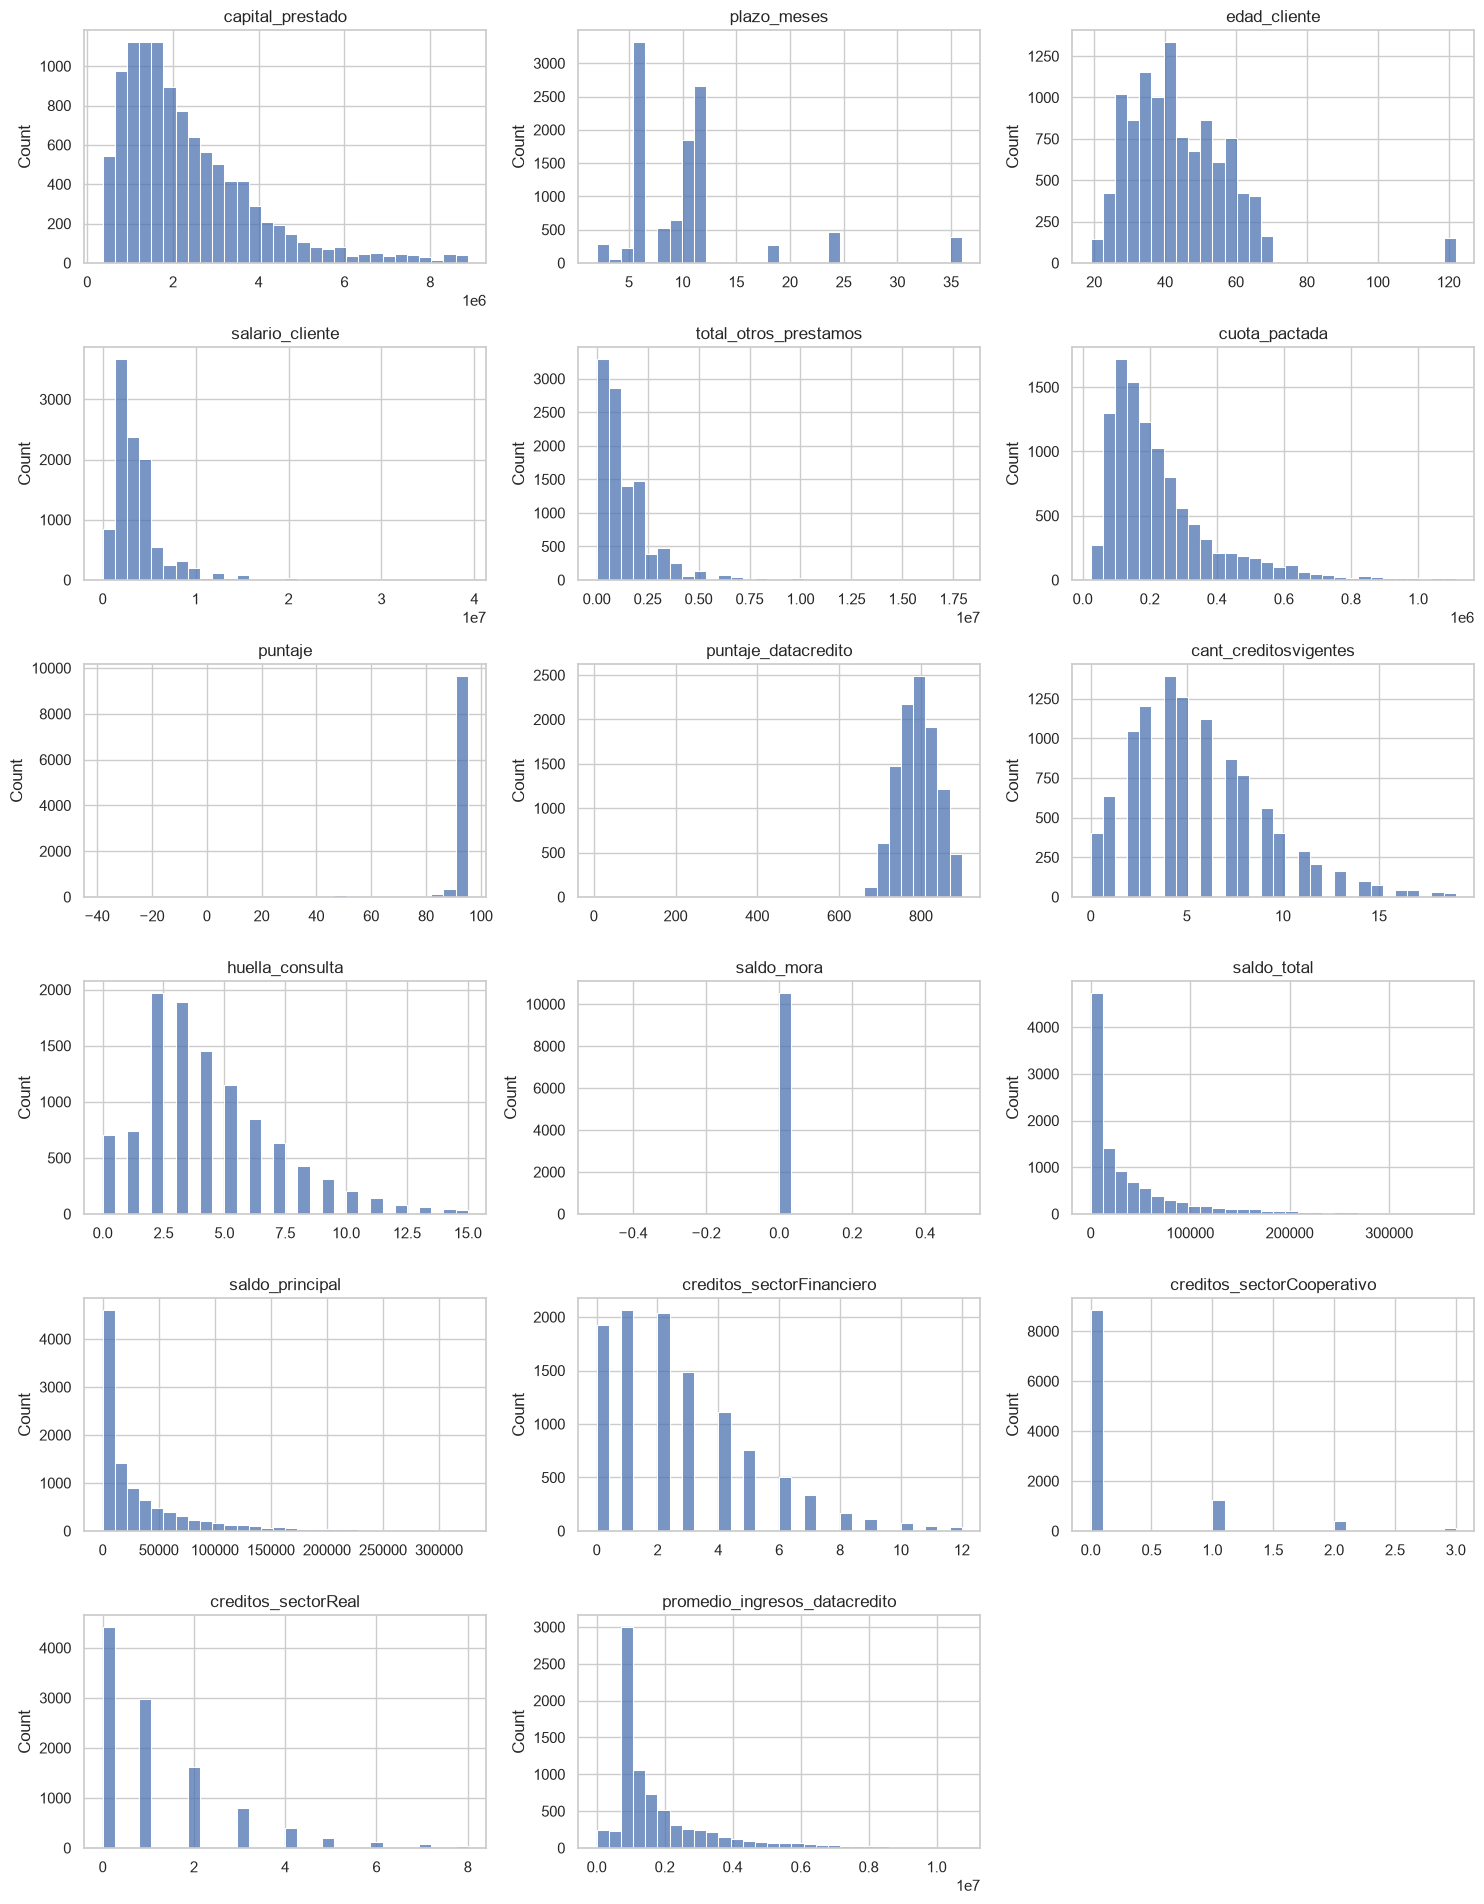

In [104]:
def grilla(columnas, funcion, ncols=3, alto=3.2):
    nrows = int(np.ceil(len(columnas) / ncols))
    fig, ejes = plt.subplots(nrows, ncols, figsize=(5 * ncols, alto * nrows))
    for eje, col in zip(ejes.flat, columnas):
        funcion(col, eje)
    for eje in list(ejes.flat)[len(columnas):]:
        eje.axis("off")
    plt.tight_layout()
    plt.show()

def sin_extremos(col):
    s = df_eda[col].dropna()
    return s[s <= s.quantile(0.99)]

grilla(NUMERICAS, lambda c, ax: (sns.histplot(sin_extremos(c), bins=30, ax=ax), ax.set_title(c), ax.set_xlabel("")))

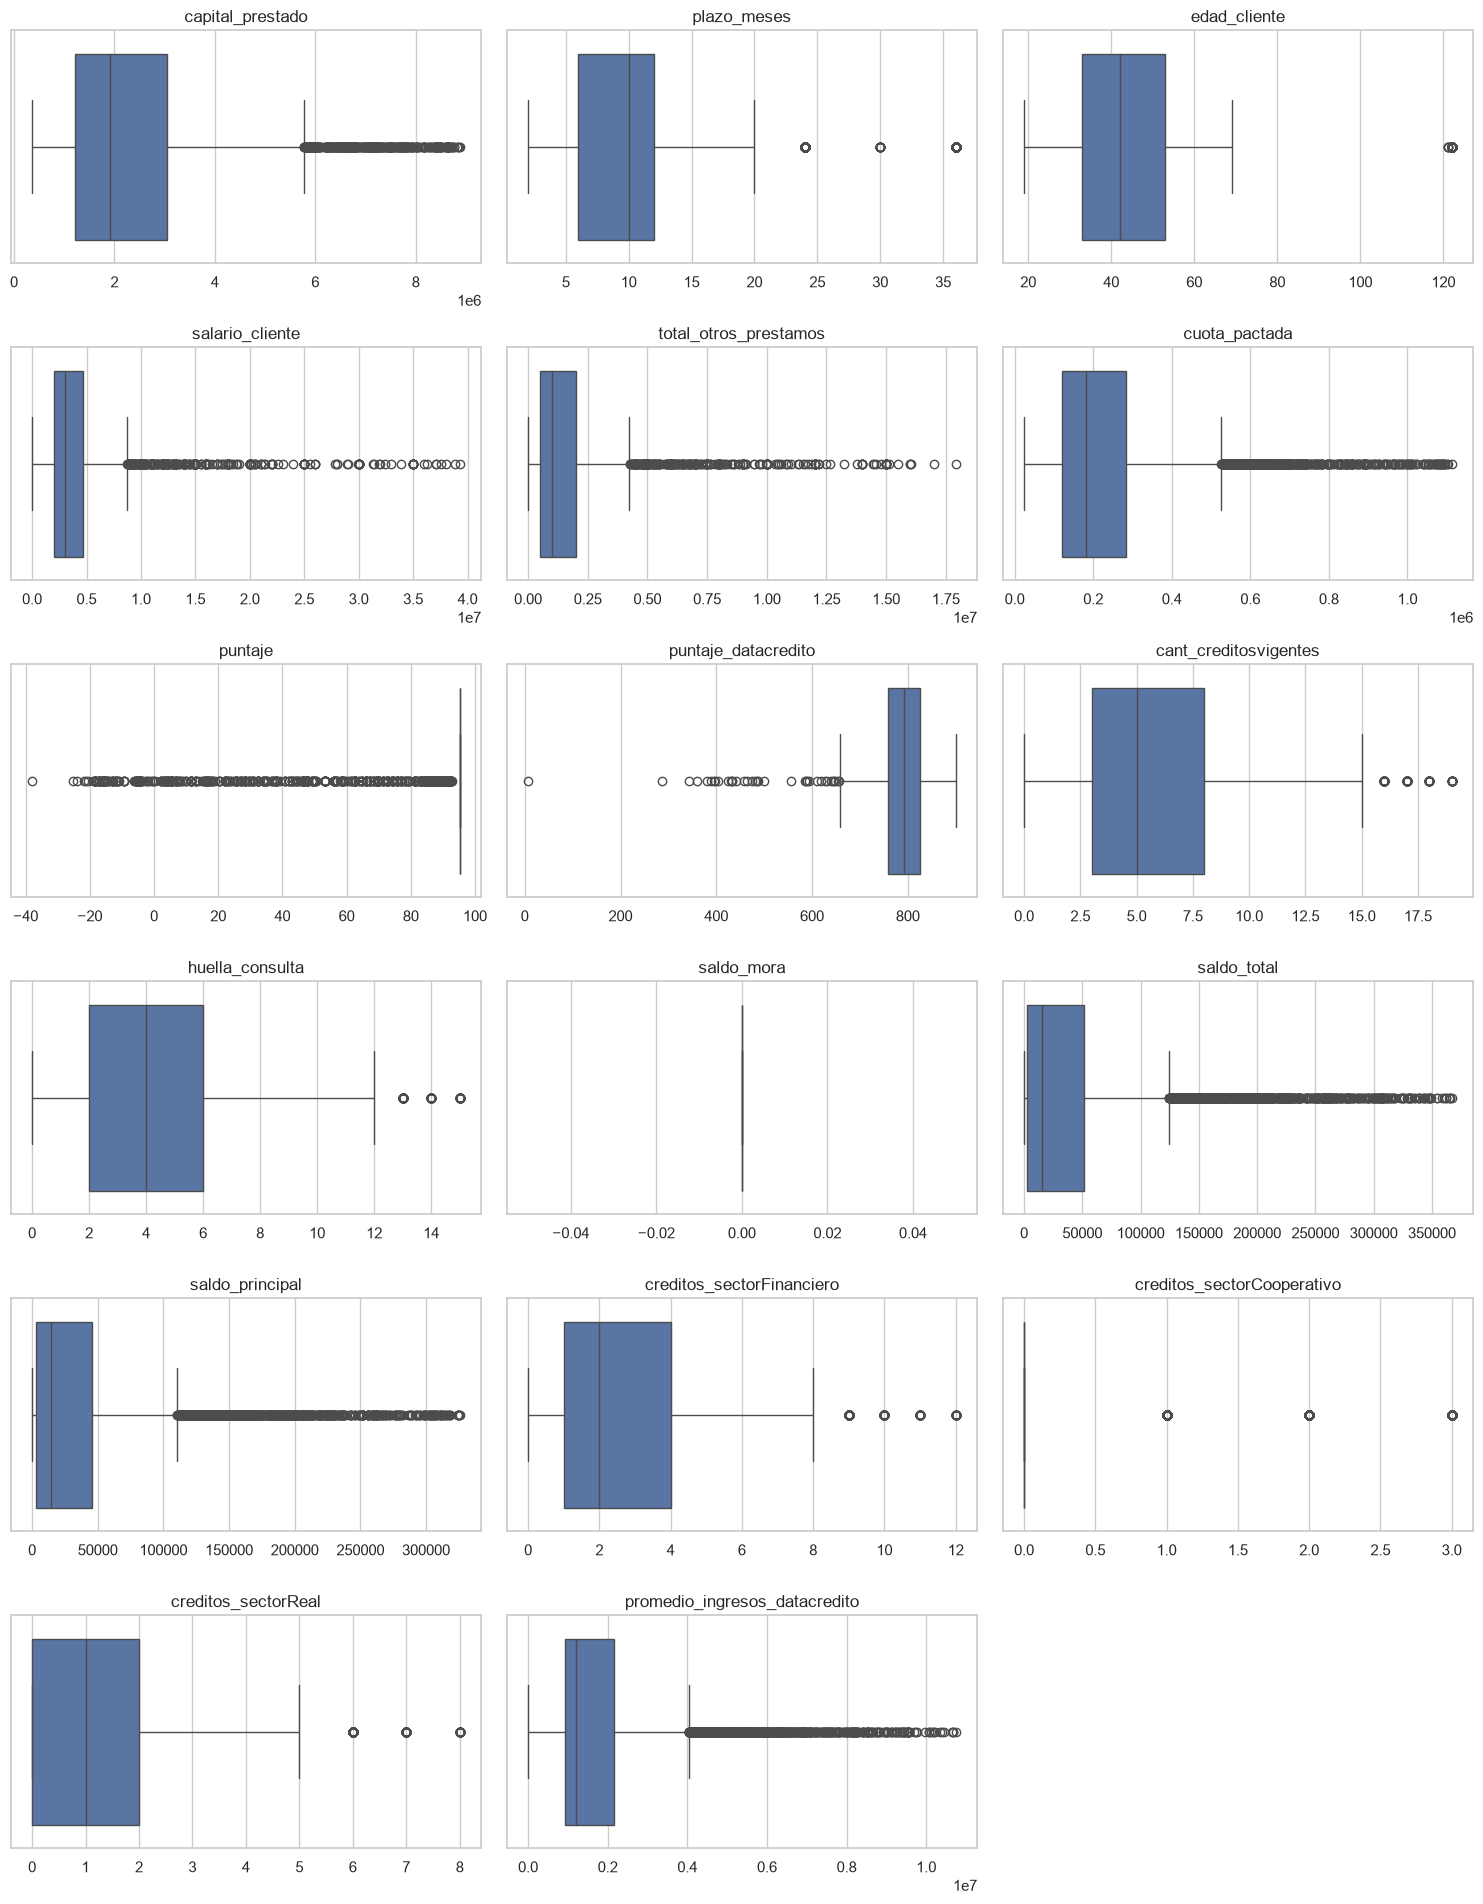

In [105]:
grilla(NUMERICAS, lambda c, ax: (sns.boxplot(x=sin_extremos(c), ax=ax), ax.set_title(c), ax.set_xlabel("")))

 Los gráficos confirman lo de la tabla:
- Los **montos** (`capital_prestado`, `cuota_pactada`, `salario_cliente`, saldos) tienen una barra alta a la izquierda y una cola larga a la derecha.
- En `edad_cliente` la mayoría está entre 25 y 65 años, y se ven valores aislados muy altos (los 122).
- `plazo_meses` se concentra en plazos cortos, con picos en 6 y 12 meses.
- `saldo_mora`, `creditos_sectorCooperativo` y `puntaje` muestran una sola barra enorme (casi todos en el mismo valor).
- `puntaje_datacredito` se concentra aproximadamente entre 700 y 880.

Por la forma de los montos, más adelante conviene aplicar una transformación (por ejemplo, logaritmo) antes de modelar (sección 6).

Variables categóricas

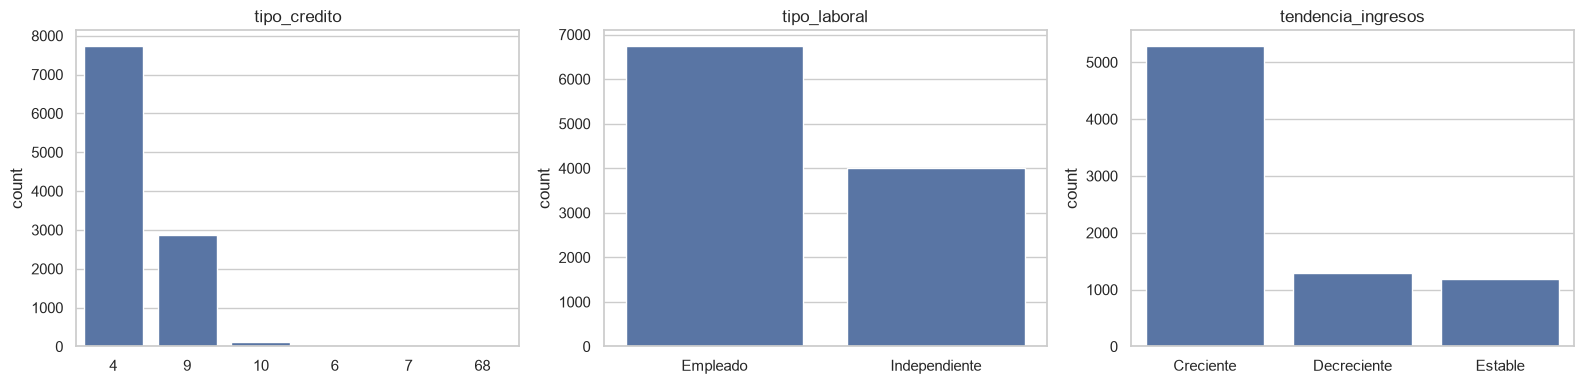

,registros,porcentaje
tipo_credito,,
4,7747,71.98
9,2876,26.72
10,116,1.08
6,21,0.20
7,2,0.02
68,1,0.01


,registros,porcentaje
tipo_laboral,,
Empleado,6754,62.75
Independiente,4009,37.25


,registros,porcentaje
tendencia_ingresos,,
Creciente,5294,49.19
NaN,2990,27.78
Decreciente,1291,11.99
Estable,1188,11.04


In [106]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
for eje, col in zip(ejes, CATEGORICAS):
    sns.countplot(x=df_eda[col], ax=eje, order=df_eda[col].value_counts().index)
    eje.set_title(col)
    eje.set_xlabel("")
plt.tight_layout()
plt.show()

for col in CATEGORICAS:
    conteo = df_eda[col].value_counts(dropna=False)
    display(pd.DataFrame({"registros": conteo, "porcentaje": (conteo / len(df_eda) * 100).round(2)}).rename_axis(col))


- `tipo_credito`: casi todo se reparte entre los códigos **4 (72 %)** y **9 (27 %)**. Los códigos 10, 6, 7 y 68 son muy poco frecuentes (116, 21, 2 y 1 registros). El 68 aparece una sola vez.
- `tipo_laboral`: 6.754 empleados (62,8 %) y 4.009 independientes (37,2 %), sin vacíos.
- `tendencia_ingresos`: predomina **Creciente** (5.294), seguida de Decreciente (1.291) y Estable (1.188). Hay **2.990 vacíos** (los 2.932 originales y los 58 inválidos que pasaron a vacío).

Los códigos de `tipo_credito` con pocos registros no permiten sacar conclusiones por separado; más adelante se pueden agrupar en una categoría "otros".

Valores extremos

In [107]:
filas = []
for c in NUMERICAS:
    s = df_eda[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    n = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
    filas.append({"variable": c, "cantidad de atípicos": n, "% atípicos": n / len(s) * 100,
                  "percentil 99": s.quantile(0.99), "máximo": s.max()})
atipicos = pd.DataFrame(filas).sort_values("% atípicos", ascending=False).set_index("variable")
display(atipicos)

print("\nLos 5 salarios más altos:", df_eda["salario_cliente"].nlargest(5).tolist())
print("Salarios mayores a 100 millones:", int((df_eda["salario_cliente"] > 100_000_000).sum()))
print("Otros préstamos mayores a 100 millones:", int((df_eda["total_otros_prestamos"] > 100_000_000).sum()))

,cantidad de atípicos,% atípicos,percentil 99,máximo
variable,,,,
creditos_sectorCooperativo,1895,17.61,3.00,13.00
puntaje,1356,12.60,95.23,95.23
promedio_ingresos_datacredito,784,10.01,"10,799,234.16","38,106,581.00"
saldo_principal,951,9.18,"325,711.87","1,562,285.00"
saldo_total,970,9.14,"367,295.26","5,116,066.00"
plazo_meses,869,8.07,36.00,90.00
cuota_pactada,765,7.11,"1,114,004.42","3,816,752.00"
salario_cliente,716,6.67,"39,726,376.82","22,000,000,000.00"
total_otros_prestamos,589,5.47,"17,946,060.00","6,787,675,263.00"



Los 5 salarios más altos: [22000000000.0, 16991100000.0, 13258352050.0, 12450806583.0, 8252584000.0]
Salarios mayores a 100 millones: 74
Otros préstamos mayores a 100 millones: 44



- Todas las variables de montos tienen valores atípicos. Los más llamativos: **74 salarios por encima de 100 millones** y **44 valores de otros préstamos por encima de 100 millones**, con máximos de 22.000 y 6.800 millones. Pueden ser errores de digitación (ceros de más), pero no se puede asegurar. También hay salarios muy bajos (el mínimo es 1.000).
- Para `puntaje`, `saldo_mora` y `creditos_sectorCooperativo` el método de los atípicos pierde sentido: como casi todo está en un valor, **cualquier dato distinto se marca como "atípico"** aunque sea normal.

No se borra ningún dato por ser extremo. Se deja la regla de validación (sección 5) y se propone limitar o transformar estos montos antes de modelar.

 Análisis bivariable (frente a Pago_atiempo)

La variable objetivo

In [108]:
objetivo = df_eda[TARGET].value_counts().sort_index()
display(pd.DataFrame({"registros": objetivo, "porcentaje": (objetivo / len(df_eda) * 100).round(2)}))

,registros,porcentaje
Pago_atiempo,,
0,511,4.75
1,10252,95.25


El **95,25 %** de los clientes tiene valor 1 (10.252) y solo el **4,75 %** tiene valor 0 (511): hay unos 20 clientes con valor 1 por cada uno con valor 0.

Si un modelo respondiera siempre "1", acertaría el 95 % de las veces sin aprender nada. Por eso, al evaluarlo no bastará con medir el porcentaje de aciertos. Además, el significado de 0 y 1 se debe confirmar con la fuente (se asume 1 = pagó a tiempo).

Variables categóricas frente al objetivo

In [109]:
for col in CATEGORICAS:
    datos = df_eda.dropna(subset=[col])
    cuenta = pd.crosstab(datos[col], datos[TARGET])
    porcentaje = (pd.crosstab(datos[col], datos[TARGET], normalize="index") * 100).round(2)
    tabla = cuenta.join(porcentaje, lsuffix=" (registros)", rsuffix=" (%)")
    print(f"--- {col} ---")
    display(tabla)

--- tipo_credito ---


Pago_atiempo,0 (registros),1 (registros),0 (%),1 (%)
tipo_credito,,,,
10,3,113,2.59,97.41
4,363,7384,4.69,95.31
6,9,12,42.86,57.14
68,0,1,0.00,100.00
7,0,2,0.00,100.00
9,136,2740,4.73,95.27


--- tipo_laboral ---


Pago_atiempo,0 (registros),1 (registros),0 (%),1 (%)
tipo_laboral,,,,
Empleado,290,6464,4.29,95.71
Independiente,221,3788,5.51,94.49


--- tendencia_ingresos ---


Pago_atiempo,0 (registros),1 (registros),0 (%),1 (%)
tendencia_ingresos,,,,
Decreciente,81,1210,6.27,93.73
Estable,55,1133,4.63,95.37
Creciente,207,5087,3.91,96.09


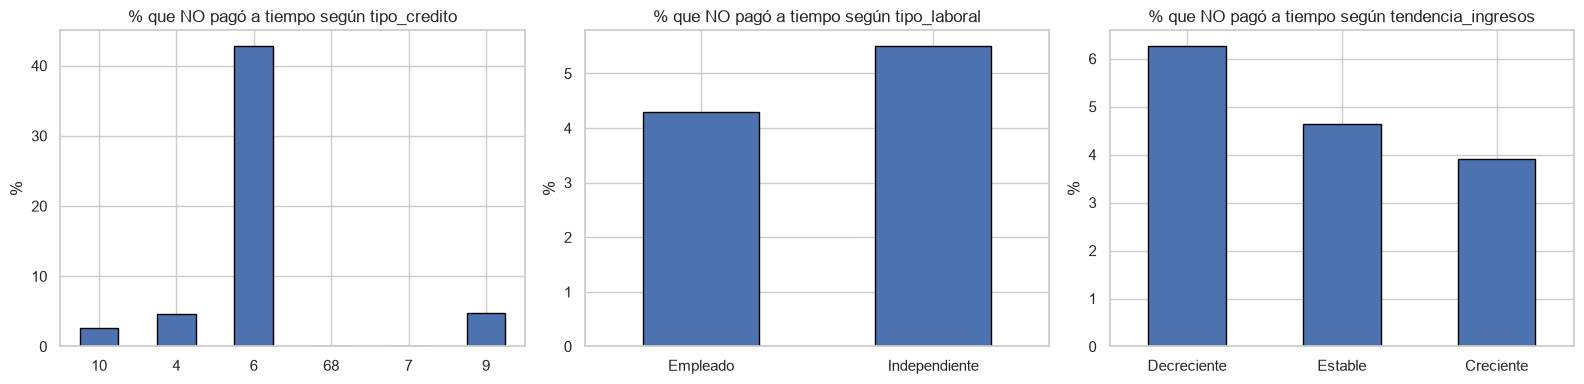

In [110]:

fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
for eje, col in zip(ejes, CATEGORICAS):
    incumplimiento = (1 - df_eda.groupby(col, observed=True)[TARGET].mean()) * 100
    incumplimiento.plot(kind="bar", ax=eje, edgecolor="black")
    eje.set_title(f"% que NO pagó a tiempo según {col}")
    eje.set_xlabel("")
    eje.set_ylabel("%")
    eje.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


- **`tipo_laboral`:** los independientes incumplen un poco más (5,51 %) que los empleados (4,29 %). La diferencia es pequeña.
- **`tendencia_ingresos`:** los clientes con ingresos decrecientes tienen más incumplimiento (6,27 %) que los estables (4,63 %) y los crecientes (3,91 %). Tiene sentido de negocio, aunque la diferencia es moderada.
- **`tipo_credito`:** los códigos 4 y 9 tienen casi el mismo comportamiento (alrededor de 4,7 % de incumplimiento). El código 10 es algo mejor (2,6 %). El **código 6 tiene 42,9 % de incumplimiento, pero son solo 21 registros**, así que no es una conclusión firme. Los códigos 7 y 68 (2 y 1 registros) no permiten concluir nada.


Variables numéricas frente al objetivo

In [111]:
medianas = df_eda.groupby(TARGET)[NUMERICAS].median().T
medianas.columns = ["Mediana si NO pagó a tiempo (0)", "Mediana si pagó a tiempo (1)"]
display(medianas)

,Mediana si NO pagó a tiempo (0),Mediana si pagó a tiempo (1)
capital_prestado,"2,268,000.00","1,908,446.40"
plazo_meses,10.00,10.00
edad_cliente,38.00,42.00
salario_cliente,"3,000,000.00","3,000,000.00"
total_otros_prestamos,"900,000.00","1,000,000.00"
cuota_pactada,"199,002.00","182,576.00"
puntaje,25.42,95.23
puntaje_datacredito,769.00,792.00
cant_creditosvigentes,5.00,5.00
huella_consulta,5.00,4.00


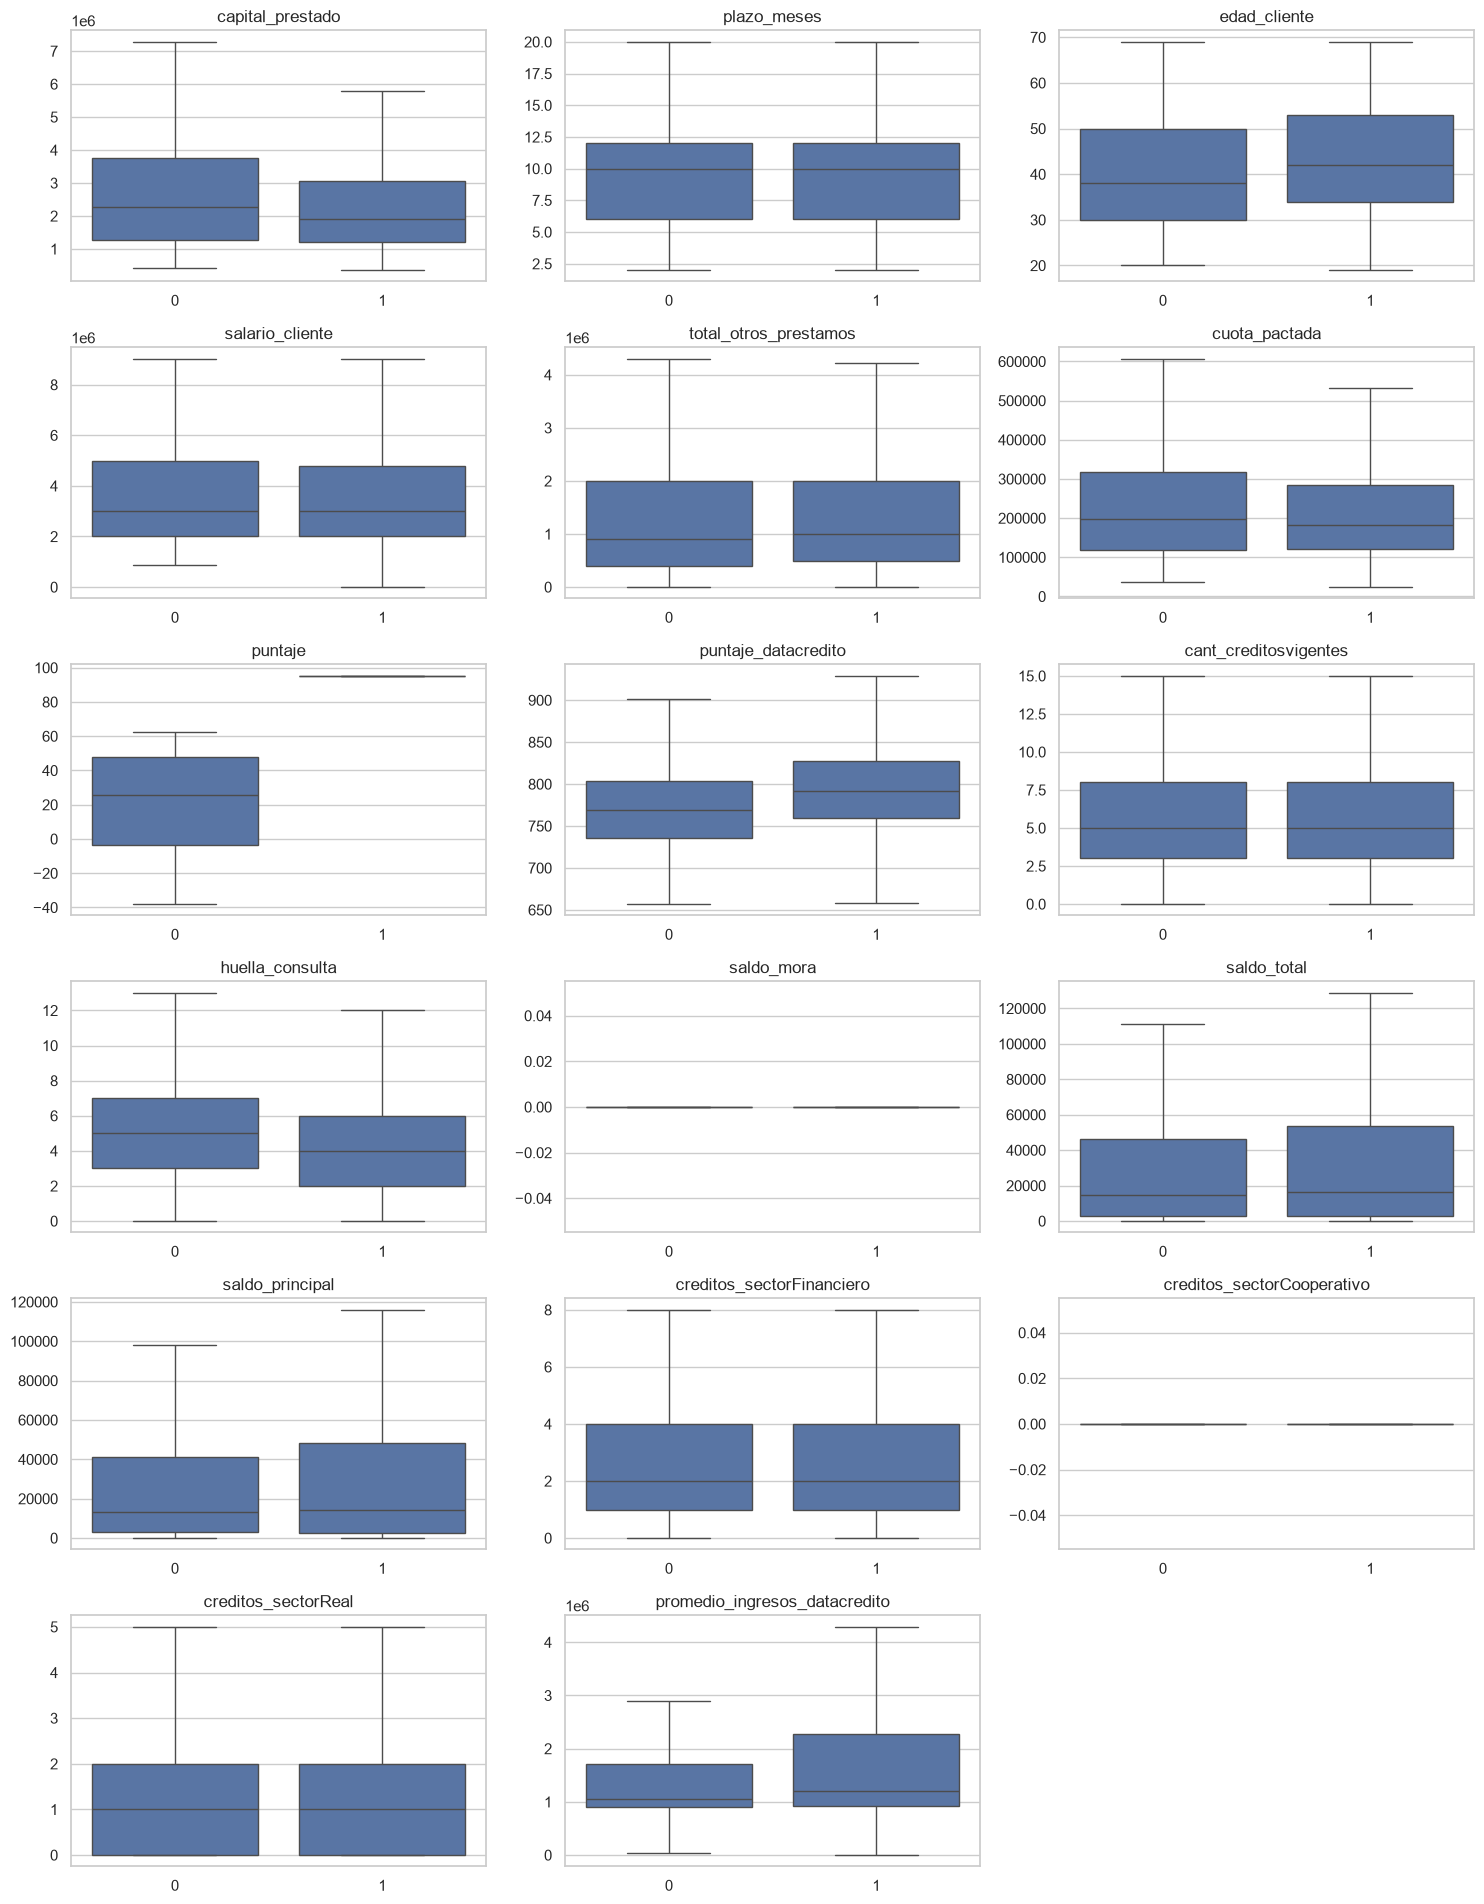

In [112]:
def caja_objetivo(col, eje):
    sns.boxplot(data=df_eda, x=TARGET, y=col, ax=eje, showfliers=False)
    eje.set_title(col)
    eje.set_xlabel("")
    eje.set_ylabel("")

grilla(NUMERICAS, caja_objetivo)

**Qué se ve** (se omiten los valores extremos en los gráficos para que se lean):
- **`puntaje`** es la única variable que separa claramente los dos grupos: mediana de 25 para quienes no pagaron a tiempo y de 95 para quienes sí. Se analiza en detalle en la siguiente sección.
- Las demás variables muestran **diferencias pequeñas**, con mucho traslape entre grupos. Quienes no pagaron a tiempo tienen, en mediana, un capital prestado mayor (2,27 frente a 1,91 millones), una cuota algo mayor, más consultas (`huella_consulta`: 5 frente a 4), un `puntaje_datacredito` algo menor (769 frente a 792) y menos edad (38 frente a 42).
- El **salario** tiene la misma mediana (3 millones) en ambos grupos: no sirve por sí solo para distinguirlos.
- El `plazo_meses` tiene la misma mediana (10), aunque entre quienes no pagaron los plazos son más variables.

**Decisión.** Ninguna variable aparte de `puntaje` tiene una relación fuerte con el objetivo por sí sola. Hará falta combinarlas en el modelo.

Revisión detallada de puntaje

In [113]:
valor_comun = df_eda["puntaje"].mode()[0]
resumen = df_eda.groupby(TARGET)["puntaje"].agg(registros="size", promedio="mean", mediana="median", mínimo="min", máximo="max")
resumen["% con el valor más común"] = df_eda.groupby(TARGET)["puntaje"].apply(lambda s: (s == valor_comun).mean() * 100)
display(resumen)

negativos = df_eda[df_eda["puntaje"] < 0]
print(f"Valor más común: {valor_comun:.6f}")
print(f"Puntajes negativos: {len(negativos)}  |  de ellos, pagaron a tiempo: {int(negativos[TARGET].sum())}")
print(f"Puntaje máximo entre quienes NO pagaron a tiempo: {df_eda.loc[df_eda[TARGET] == 0, 'puntaje'].max():.2f}")
print(f"Puntaje mínimo entre quienes SÍ pagaron a tiempo: {df_eda.loc[df_eda[TARGET] == 1, 'puntaje'].min():.2f}")

,registros,promedio,mediana,mínimo,máximo,% con el valor más común
Pago_atiempo,,,,,,
0,511,23.09,25.42,-38.01,62.67,0.00
1,10252,94.56,95.23,63.81,95.23,91.76


Valor más común: 95.227787
Puntajes negativos: 135  |  de ellos, pagaron a tiempo: 0
Puntaje máximo entre quienes NO pagaron a tiempo: 62.67
Puntaje mínimo entre quienes SÍ pagaron a tiempo: 63.81


**Qué se ve.**
- Entre quienes **no pagaron a tiempo**, el puntaje va de −38 a 62,7. Entre quienes **sí pagaron**, va de 63,8 a 95,2.
- **Un solo umbral (alrededor de 63) separa los dos grupos sin ningún traslape.** Ninguna otra variable hace algo parecido.
- El 91,8 % de quienes pagaron a tiempo tiene exactamente el puntaje 95,227787, que parece un **tope máximo**.
- Los **135 puntajes negativos** corresponden todos a clientes que no pagaron a tiempo.
- La correlación entre `puntaje` y `Pago_atiempo` es de 0,92; la siguiente variable es `puntaje_datacredito`, con solo 0,12.

**Por qué es importante.** Esto es una señal de alerta de **fuga de datos** (*data leakage*): el puntaje podría haberse calculado **después** de saber si el cliente pagó, o incluir esa información. Un modelo que lo use parecería casi perfecto en las pruebas, pero **no serviría en la vida real**, porque al momento de aprobar un crédito no se conoce ese resultado.

**Decisión.** `puntaje` **no se debe usar como variable del modelo** hasta confirmar con la fuente cómo se calcula y si está disponible antes de otorgar el crédito. No se modifica ni se elimina de la base.

Análisis multivariable

Correlaciones entre variables numéricas

*La correlación va de −1 a 1: cerca de 1, las dos variables suben juntas; cerca de −1, una sube cuando la otra baja; cerca de 0, no hay relación lineal.*

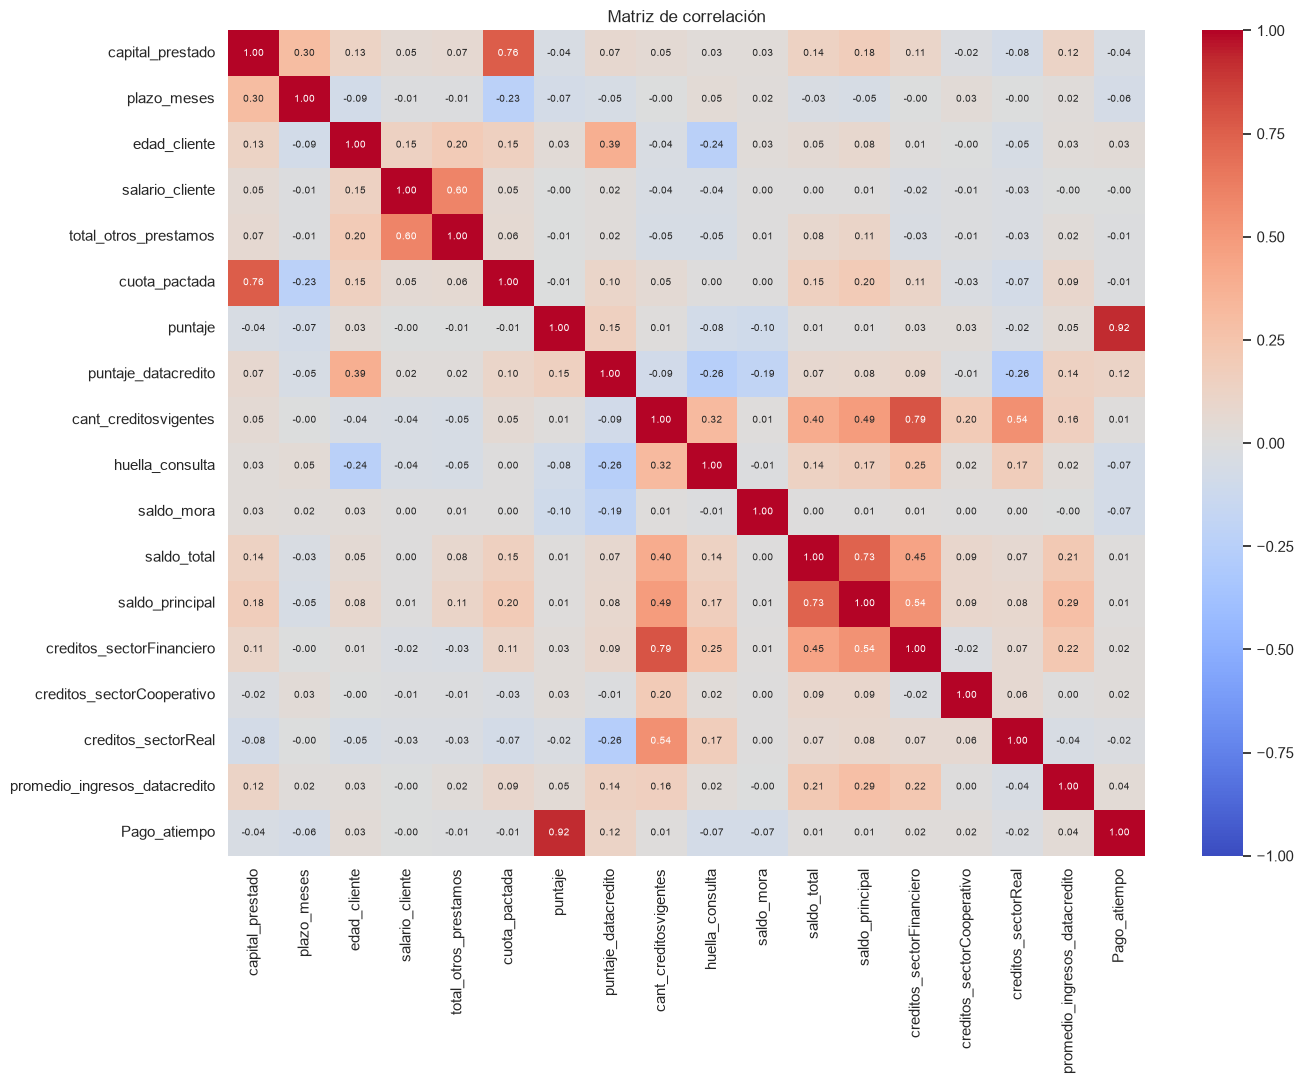

Correlación de cada variable con Pago_atiempo:


,correlación
puntaje,0.92
puntaje_datacredito,0.12
huella_consulta,-0.07
saldo_mora,-0.07
plazo_meses,-0.06
capital_prestado,-0.04
promedio_ingresos_datacredito,0.04
edad_cliente,0.03
creditos_sectorReal,-0.02
creditos_sectorFinanciero,0.02



Pares de variables con correlación mayor a 0,6 (en valor absoluto):


,,correlación
puntaje,Pago_atiempo,0.92
cant_creditosvigentes,creditos_sectorFinanciero,0.79
capital_prestado,cuota_pactada,0.76
saldo_total,saldo_principal,0.73


In [114]:
corr = df_eda[NUMERICAS + [TARGET]].corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

print("Correlación de cada variable con Pago_atiempo:")
display(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).to_frame("correlación"))

pares = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print("\nPares de variables con correlación mayor a 0,6 (en valor absoluto):")
display(pares[pares.abs() > 0.6].sort_values(key=abs, ascending=False).to_frame("correlación"))


- Con el objetivo, solo `puntaje` tiene una correlación alta (0,92). Las demás son muy bajas: la mayor es `puntaje_datacredito` (0,12) y el resto no llega a 0,08 en valor absoluto. Al pasar los ceros de `puntaje_datacredito` a vacío (sección 1.4), su correlación subió de 0,07 a 0,12, lo que apoya esa decisión.
- Entre las variables hay algunas relaciones esperables: **`capital_prestado` y `cuota_pactada`** (0,76: a mayor préstamo, mayor cuota), **`cant_creditosvigentes` y `creditos_sectorFinanciero`** (0,79: la mayoría de los créditos vigentes son del sector financiero) y **`saldo_total` y `saldo_principal`** (0,74).
- Esas parejas comparten parte de su información. No es motivo para eliminarlas ya, pero se tendrá en cuenta al elegir variables.

Gráficos de dispersión con color según el objetivo

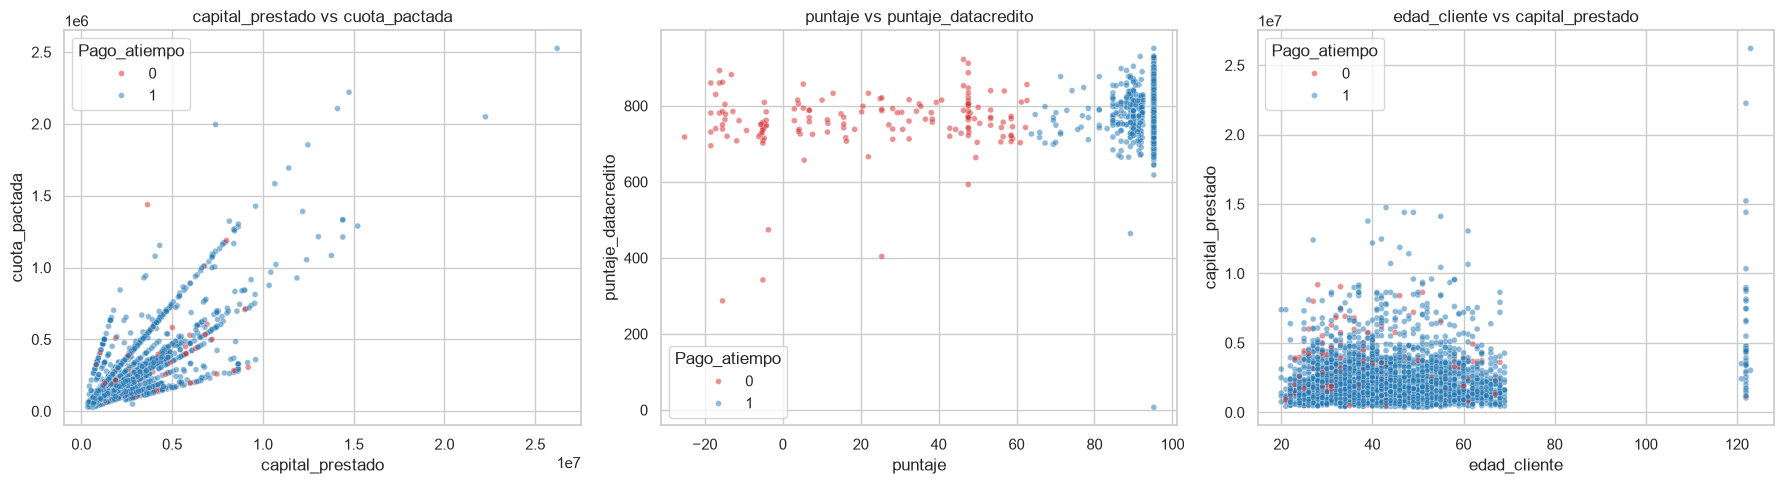

In [115]:
muestra = df_eda.sample(3000, random_state=1)
parejas = [("capital_prestado", "cuota_pactada"), ("puntaje", "puntaje_datacredito"), ("edad_cliente", "capital_prestado")]

fig, ejes = plt.subplots(1, 3, figsize=(18, 5))
for eje, (x, y) in zip(ejes, parejas):
    sns.scatterplot(data=muestra, x=x, y=y, hue=TARGET, palette={0: "tab:red", 1: "tab:blue"}, alpha=0.5, s=18, ax=eje)
    eje.set_title(f"{x} vs {y}")
plt.tight_layout()
plt.show()

**Qué se ve** (muestra de 3.000 registros; rojo = no pagó a tiempo, azul = sí pagó):
- **Capital y cuota:** suben juntos, como indicaba la correlación. Los clientes que no pagaron (rojo) están repartidos entre los demás, sin una zona propia.
- **Puntaje y `puntaje_datacredito`:** los dos grupos se separan según `puntaje` (eje horizontal; los rojos quedan a la izquierda y los azules a la derecha) pero **no por `puntaje_datacredito`**. Esto confirma que `puntaje` es el que "hace la diferencia".
- **Edad y capital:** no se ve ningún patrón claro; los incumplimientos están mezclados con todos los demás.

Relación entre variables categóricas y matriz de pares

In [116]:
print("Tipo de crédito según tipo laboral (% dentro de cada tipo laboral):")
display((pd.crosstab(df_eda["tipo_laboral"], df_eda["tipo_credito"], normalize="index") * 100).round(1))

print("\nTendencia de ingresos según tipo laboral (% dentro de cada tipo laboral):")
display((pd.crosstab(df_eda["tipo_laboral"], df_eda["tendencia_ingresos"], normalize="index") * 100).round(1))

Tipo de crédito según tipo laboral (% dentro de cada tipo laboral):


tipo_credito,10,4,6,68,7,9
tipo_laboral,,,,,,
Empleado,1.10,74.80,0.30,0.00,0.00,23.70
Independiente,1.00,67.20,0.00,0.00,0.00,31.70



Tendencia de ingresos según tipo laboral (% dentro de cada tipo laboral):


tendencia_ingresos,Decreciente,Estable,Creciente
tipo_laboral,,,
Empleado,17.30,11.90,70.80
Independiente,15.10,23.10,61.80


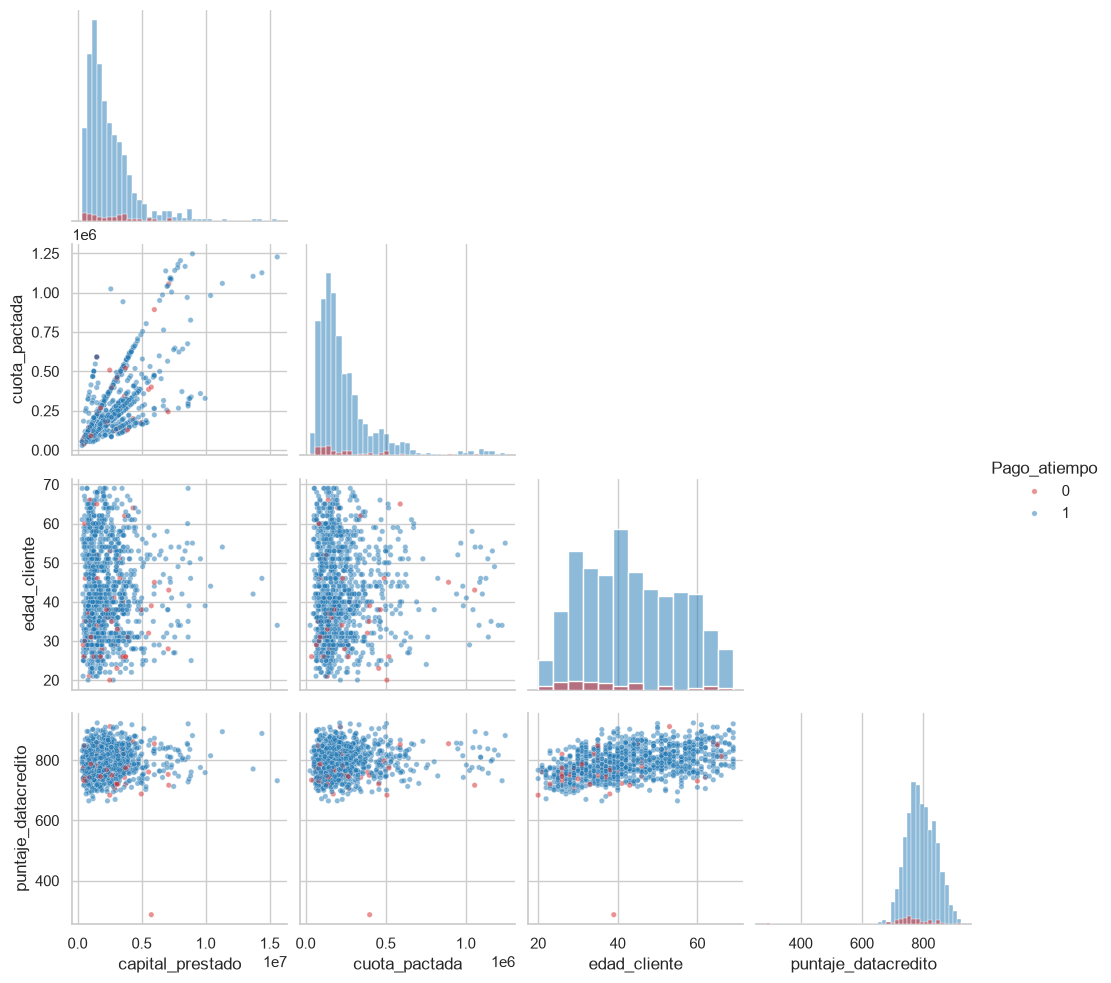

In [117]:
variables_pares = ["capital_prestado", "cuota_pactada", "edad_cliente", "puntaje_datacredito", TARGET]
muestra_pares = df_eda[variables_pares].dropna().sample(1000, random_state=1)
sns.pairplot(muestra_pares, hue=TARGET, palette={0: "tab:red", 1: "tab:blue"},
             corner=True, diag_kind="hist", plot_kws={"alpha": 0.5, "s": 15})
plt.show()


- Entre los **independientes** hay más créditos de tipo 9 (31,7 %) que entre los empleados (23,7 %).
- En el `pairplot` solo se destaca la relación entre capital y cuota. Las otras parejas no muestran patrones y los dos grupos del objetivo se mezclan.

**Conclusión de esta sección:** las variables, tomadas de a dos, casi no separan a quienes pagan de quienes no. Esto hace todavía más importante aclarar qué es `puntaje`: es la única que lo hace.

Reglas de validación de los datos

Estas reglas se definen a partir de lo encontrado en el análisis. Servirán en otra etapa del proyecto para revisar automáticamente que los datos nuevos que lleguen estén en buen estado. La tabla siguiente cuenta **cuántos registros de esta base las incumplen**.

In [118]:
hoy = pd.Timestamp.today()
reglas = pd.DataFrame([
    ("edad_cliente",        "Entre 18 y 100 años",                                ((df.edad_cliente < 18) | (df.edad_cliente > 100)).sum()),
    ("salario_cliente",     "Mayor que 0",                                        (df.salario_cliente <= 0).sum()),
    ("salario_cliente",     "Menor a un máximo razonable (provisional: 100 millones)", (df.salario_cliente > 100_000_000).sum()),
    ("total_otros_prestamos", "Mayor o igual a 0 y menor a un máximo razonable (provisional: 100 millones)",
        ((df.total_otros_prestamos < 0) | (df.total_otros_prestamos > 100_000_000)).sum()),
    ("capital_prestado",    "Mayor que 0",                                        (df.capital_prestado <= 0).sum()),
    ("plazo_meses",         "Entre 1 y 48 meses (el 90 se valida con el negocio)", ((df.plazo_meses < 1) | (df.plazo_meses > 48)).sum()),
    ("puntaje",             "Mayor o igual a 0 (rango por confirmar)",            (df.puntaje < 0).sum()),
    ("puntaje_datacredito", "Mayor que 0 (rango por confirmar)",                  (df.puntaje_datacredito <= 0).sum()),
    ("tendencia_ingresos",  "Solo Creciente, Decreciente o Estable (o vacío)",    int(df_eda["tendencia_invalida"].sum())),
    ("tipo_credito",        "Código del catálogo conocido: 4, 6, 7, 9 o 10",      (~df.tipo_credito.isin([4, 6, 7, 9, 10])).sum()),
    ("tipo_laboral",        "Solo Empleado o Independiente",                      (~df.tipo_laboral.isin(["Empleado", "Independiente"])).sum()),
    ("Pago_atiempo",        "Solo 0 o 1",                                         (~df.Pago_atiempo.isin([0, 1])).sum()),
    ("fecha_prestamo",      "Fecha válida y no futura",                           int((df_eda.fecha_prestamo.isna() | (df_eda.fecha_prestamo > hoy)).sum())),
    ("toda la base",        "Sin filas duplicadas",                               df.duplicated().sum()),
], columns=["variable", "regla", "registros que no la cumplen"])
display(reglas)

,variable,regla,registros que no la cumplen
0,edad_cliente,Entre 18 y 100 años,150
1,salario_cliente,Mayor que 0,24
2,salario_cliente,Menor a un máximo razonable (provisional: 100 ...,74
3,total_otros_prestamos,Mayor o igual a 0 y menor a un máximo razonabl...,44
4,capital_prestado,Mayor que 0,0
5,plazo_meses,Entre 1 y 48 meses (el 90 se valida con el neg...,1
6,puntaje,Mayor o igual a 0 (rango por confirmar),135
7,puntaje_datacredito,Mayor que 0 (rango por confirmar),146
8,tendencia_ingresos,"Solo Creciente, Decreciente o Estable (o vacío)",58
9,tipo_credito,"Código del catálogo conocido: 4, 6, 7, 9 o 10",1


| Variable | Qué se encontró | Acción propuesta |
|---|---|---|
| `edad_cliente` | 150 clientes de más de 100 años (144 con exactamente 122) | Marcar como sospechosos; pasar a vacío al preparar los datos |
| `salario_cliente` | 24 salarios en 0 y 74 por encima de 100 millones (máximo: 22.000 millones) | 0 → vacío; limitar o revisar los extremos con el negocio |
| `total_otros_prestamos` | 44 valores por encima de 100 millones | Igual que el salario |
| `plazo_meses` | Valores entre 2 y 90 meses; solo 1 registro supera los 48 | Validar con las condiciones de los productos |
| `puntaje` | 135 negativos y 87 % en un solo valor (95,23) | Confirmar su origen; **no usar en el modelo** mientras tanto |
| `puntaje_datacredito` | 145 ceros y 1 negativo | Pasar a vacío (probablemente "sin puntaje") |
| `tendencia_ingresos` | 58 valores numéricos en lugar de categorías | Pasar a vacío y marcar; revisar cómo se cargaron |
| `tipo_credito` | El código 68 aparece una sola vez; 6 y 7 muy pocas | Confirmar el catálogo; agrupar los poco frecuentes en "otros" |
| `Pago_atiempo` | Solo 0 y 1, con 95 % de unos | Confirmar el significado de cada valor |
| Datos nuevos | Vacíos aceptables: tendencia y promedio de ingresos (27 %), saldos (1 % a 5 %) | Definir si un vacío es aceptable o rechaza el registro |

Transformaciones que se podrían aplicar

Aquí solo se **identifican** las transformaciones; se aplicarán en la etapa de ingeniería de características.

| Variable(s) | Transformación propuesta | Por qué |
|---|---|---|
| `capital_prestado`, `cuota_pactada`, `salario_cliente`, `total_otros_prestamos`, `saldo_total`, `saldo_principal` | Logaritmo (o limitar los extremos) | Están muy sesgadas a la derecha y tienen valores extremos que distorsionan |
| `tipo_credito` | Agrupar los códigos poco frecuentes (6, 7, 10, 68) en "otros" y luego codificar | Hay códigos con 1 a 21 registros que no permiten sacar conclusiones |
| `tipo_laboral` | Codificar como 0/1 | Solo tiene dos valores |
| `tendencia_ingresos` | Codificar con orden (Decreciente < Estable < Creciente) y una categoría "sin información" | Es ordinal y tiene 27 % de vacíos con significado propio |
| `promedio_ingresos_datacredito`, saldos | Rellenar vacíos (por ejemplo, con la mediana) más un indicador "estaba vacío" | Los vacíos no son aleatorios |
| `edad_cliente`, `salario_cliente`, `puntaje_datacredito` | Pasar los valores imposibles a vacío antes de rellenar | Son errores probables (122 años, salario 0) |
| Variables numéricas | Escalar (si el modelo lo requiere) | Tienen unidades muy distintas (años, millones, conteos) |
| `Pago_atiempo` | Tener en cuenta el desbalance (95 % / 5 %) al entrenar y evaluar | Un modelo podría acertar mucho sin aprender nada |

Atributos derivados que pueden ser útiles

Son variables nuevas, calculadas a partir de las existentes, que podrían ayudar al modelo.

In [119]:
derivadas = pd.DataFrame(index=df_eda.index)
derivadas["cuota_sobre_salario"] = df_eda["cuota_pactada"] / df_eda["salario_cliente"]
derivadas["capital_sobre_salario"] = df_eda["capital_prestado"] / df_eda["salario_cliente"]
derivadas["otros_prestamos_sobre_salario"] = df_eda["total_otros_prestamos"] / df_eda["salario_cliente"]
derivadas["tiene_mora"] = (df_eda["saldo_mora"] > 0).astype(int)
derivadas["sin_datos_ingresos"] = df_eda["promedio_ingresos_datacredito"].isna().astype(int)
derivadas["mes_prestamo"] = df_eda["fecha_prestamo"].dt.month
derivadas = derivadas.replace([np.inf, -np.inf], np.nan)

display(derivadas.describe().T[["count", "mean", "50%", "max"]])

print("Correlación de cada variable derivada con Pago_atiempo:")
display(derivadas.join(df_eda[TARGET]).corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).to_frame("correlación"))

,count,mean,50%,max
cuota_sobre_salario,"10,739.00",0.09,0.06,125.80
capital_sobre_salario,"10,739.00",0.92,0.63,840.00
otros_prestamos_sobre_salario,"10,739.00",0.69,0.33,"2,439.00"
tiene_mora,"10,763.00",0.01,0.00,1.00
sin_datos_ingresos,"10,763.00",0.27,0.00,1.00
mes_prestamo,"10,763.00",5.27,4.00,12.00


Correlación de cada variable derivada con Pago_atiempo:


,correlación
tiene_mora,-0.11
sin_datos_ingresos,-0.03
mes_prestamo,0.01
otros_prestamos_sobre_salario,0.00
cuota_sobre_salario,0.00
capital_sobre_salario,-0.00


| Variable derivada | Cómo se calcula | Por qué podría servir |
|---|---|---|
| `cuota_sobre_salario` | cuota ÷ salario | Mide qué parte del ingreso se va en la cuota (capacidad de pago) |
| `capital_sobre_salario` | capital prestado ÷ salario | Qué tan grande es el préstamo frente a lo que gana el cliente |
| `otros_prestamos_sobre_salario` | otros préstamos ÷ salario | Nivel de endeudamiento |
| `tiene_mora` | 1 si `saldo_mora` > 0 | Convierte una variable casi toda en cero en una señal clara |
| `sin_datos_ingresos` | 1 si falta el promedio de ingresos | Aprovecha que el vacío tiene significado propio |
| `mes_prestamo` | mes de `fecha_prestamo` | Permite ver si hay estacionalidad |

La que más se relaciona con el objetivo es tiene_mora (correlación de −0,11, similar a la de las mejores variables originales distintas de `puntaje`): los clientes con mora pagan a tiempo bastante menos. Las razones sobre el salario y el mes casi no muestran relación lineal con el objetivo (cerca de 0), pero se conservan como candidatas porque tienen sentido de negocio y habrá que probar su utilidad en el modelo.

Conclusiones



1. La base tiene **10.763 créditos y 23 variables**, sin filas duplicadas. La variable objetivo está muy **desbalanceada**: el 95,25 % pagó a tiempo y solo el 4,75 % no.
2. **Calidad de los datos:** se encontraron vacíos (sobre todo en `tendencia_ingresos` y `promedio_ingresos_datacredito`, 27 % cada una, casi siempre juntos), 58 valores numéricos en una variable de categorías, 150 edades de más de 100 años (144 con exactamente 122), ceros que significan "sin dato" y montos extremos (salarios de hasta 22.000 millones).
3. Los **vacíos de ingresos no parecen aleatorios**: corresponden a clientes con otro perfil (más independientes y de mayor edad), por lo que conviene tratarlos con un indicador propio.
4. Los **montos** están muy sesgados a la derecha y necesitarán una transformación. Los **conteos** y los saldos están concentrados en valores bajos o en cero.
5. **`puntaje` separa perfectamente a quienes pagan de quienes no** (un umbral de ~63 los divide sin traslape) y tiene un tope en 95,23. Es una señal clara de posible **fuga de datos**: no debe usarse en el modelo hasta confirmar su origen.
6. Las **demás variables tienen relaciones débiles** con el pago a tiempo por separado. Las más destacables son tener **mora** (63,6 % de pago frente a 95,5 %), una **tendencia de ingresos decreciente** y ser **independiente**. Habrá que combinar varias para predecir.
7. Se eliminó `saldo_mora_codeudor` (solo 3 valores distintos de cero) y se dejaron escritas las **reglas de validación**, las **transformaciones** y los **atributos derivados** para las siguientes etapas.
